# 01 — Simulations and theory
Loads the simulations and makes the paper figures, now with the branching-process / deterministic theory overlaid. Therefore, this notebook does not concern comparison with real data just yet. 

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    import lovelyplots
    plt.style.use('ipynb')
except Exception:
    sns.set_style('ticks')
sys.path.append('..')
from sir_sim import *

RESULTS = 'results' 
FIGS = 'figures'
os.makedirs(FIGS, exist_ok=True)

grid = load_grid(RESULTS)
N_all = sorted({k[0] for k in grid})
eps_all = sorted({k[1] for k in grid})
print(f'{len(grid)} (N, eps) combinations loaded; N = {N_all}')

180 (N, eps) combinations loaded; N = [1000, 2000, 5000, 10000, 20000, 50000, 100000, 200000, 500000]


In [2]:
# values used in the paper figures
N_vec = [1000, 5000, 10000, 50000, 100000, 500000]
eps_vec = [-0.05, -0.03, -0.01, 0, 0.01, 0.03, 0.05, 0.1]
palette = sns.color_palette('tab10', len(N_vec))
colors = dict(zip(N_vec, palette))

# summaries for every (N, eps): p_s, p_b, conditional mean sizes
tab = ps_table(grid)
eps_fine = np.linspace(-0.05, 0.1, 600)
tab.head()

,N,eps,threshold,p_s,p_b,se_p,mean_small_cases,mean_big_cases
0,1000,-0.050,inf,1.0,0.0,0.0,1.9128,NaN
1,1000,-0.040,inf,1.0,0.0,0.0,2.2950,NaN
2,1000,-0.030,inf,1.0,0.0,0.0,2.8376,NaN
3,1000,-0.020,inf,1.0,0.0,0.0,3.5917,NaN
4,1000,-0.015,inf,1.0,0.0,0.0,4.0762,NaN


# Figure 1
Final-size distribution for N = 1000 at each ε. Dotted line: deterministic final size.

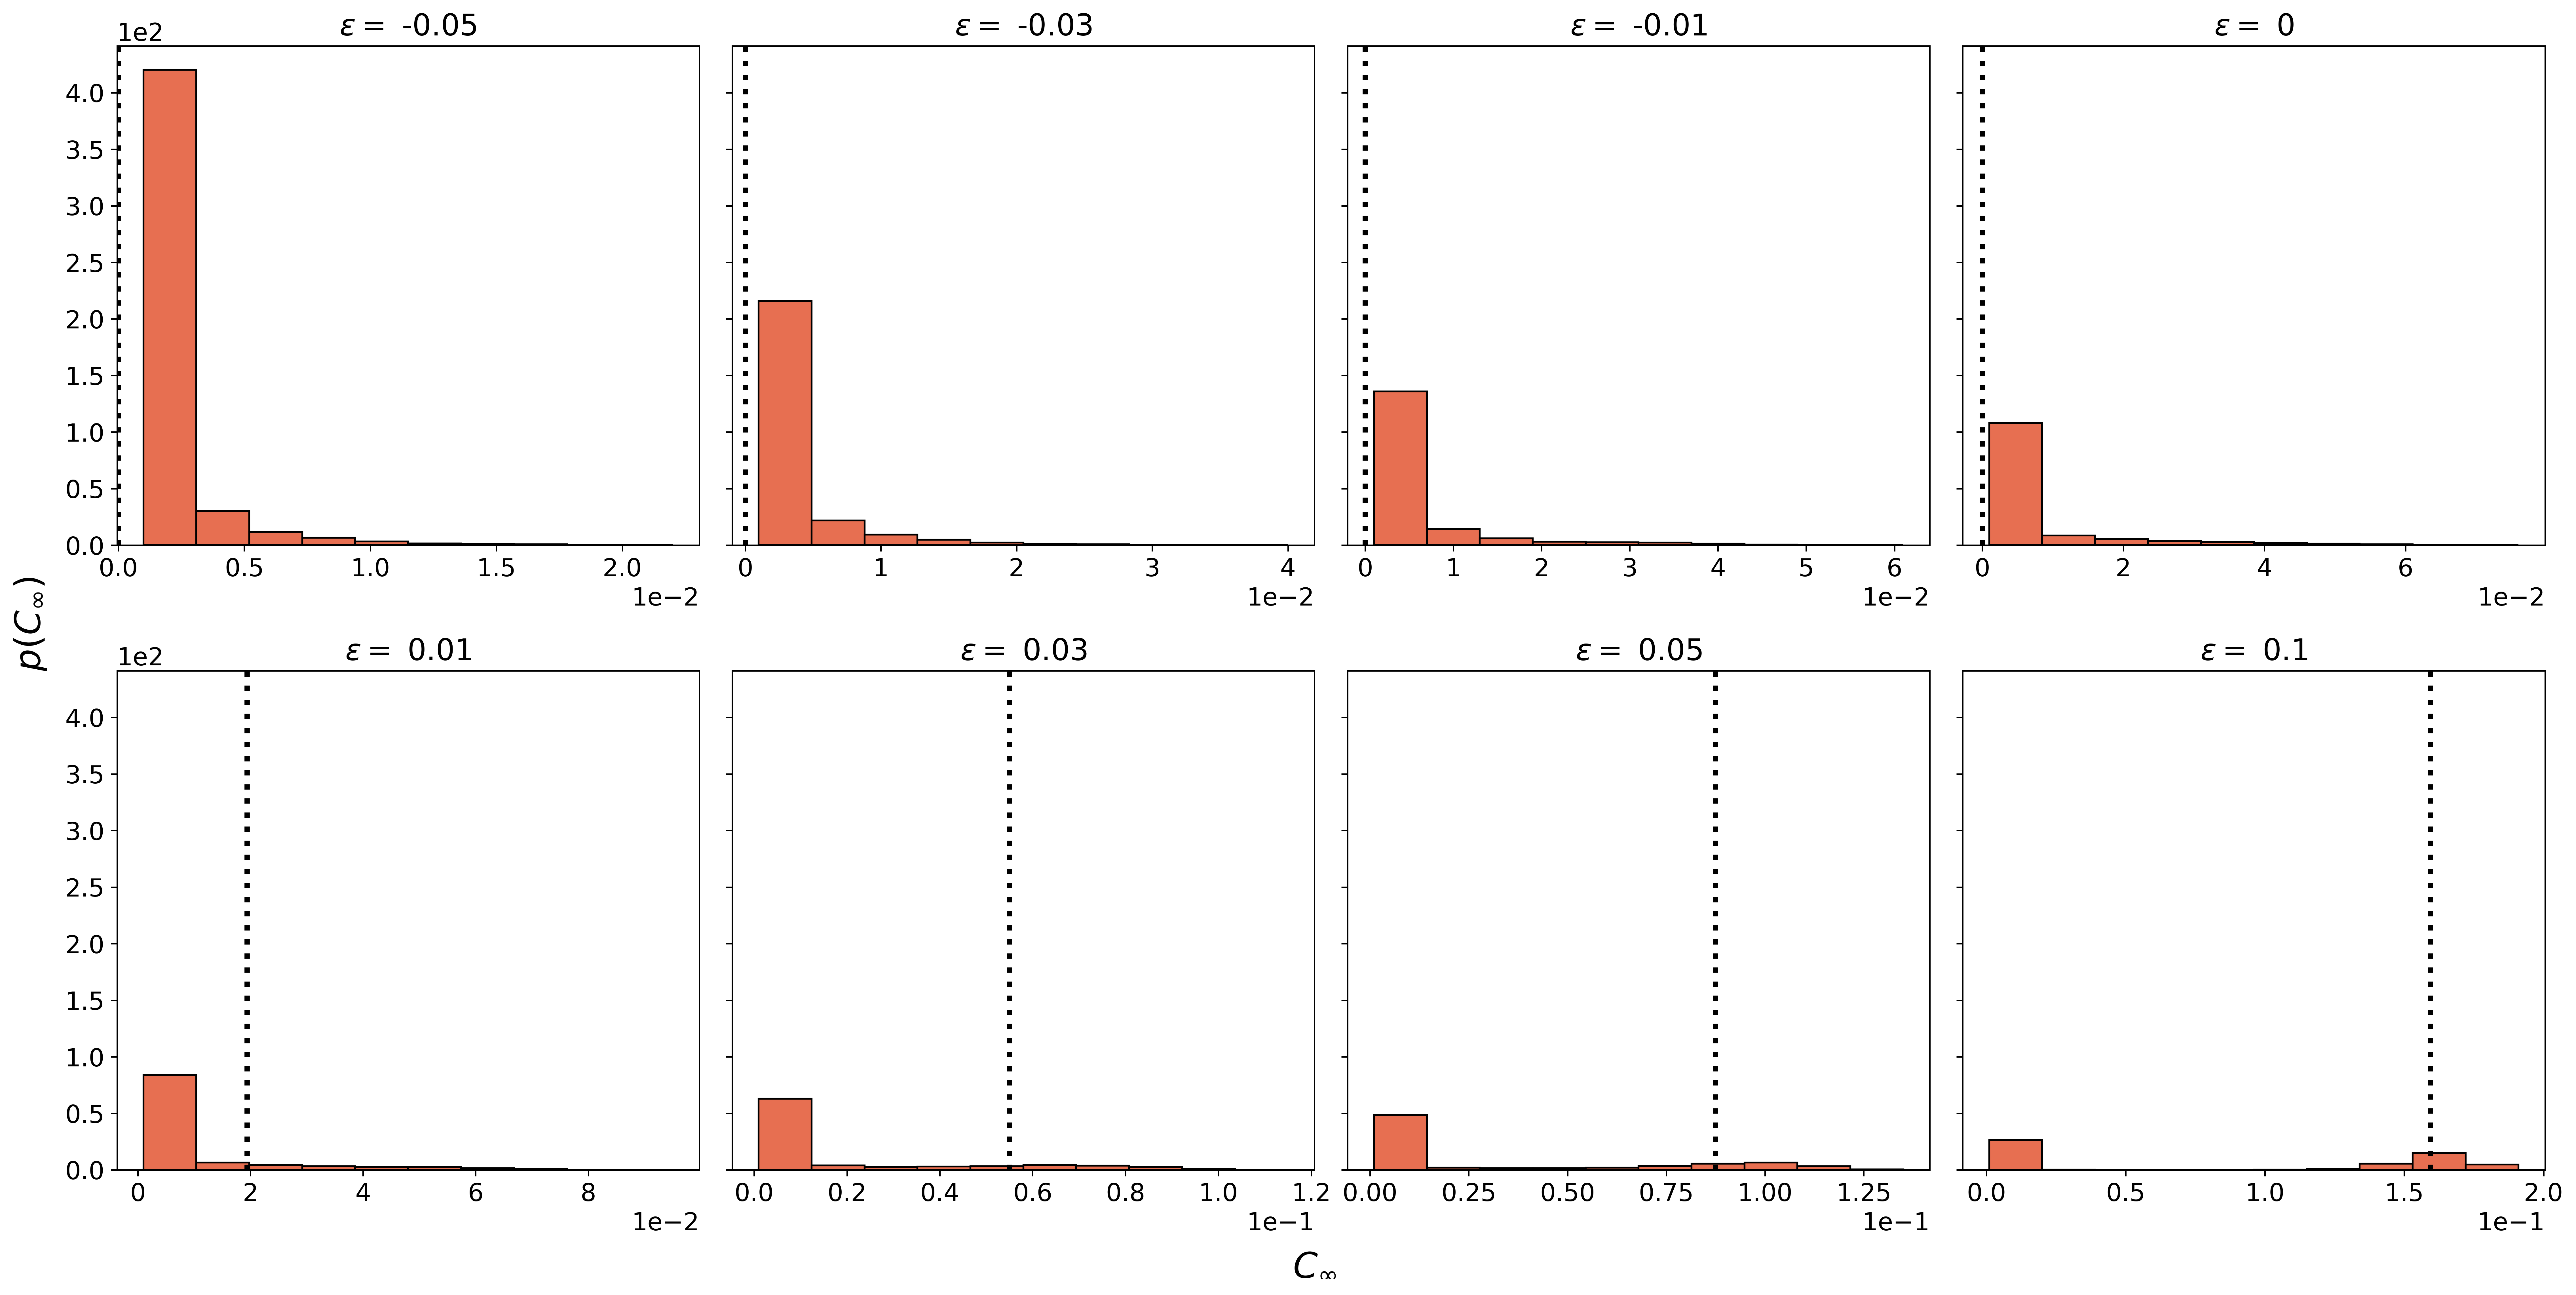

In [3]:
N = 1000
fig, axs = plt.subplots(2, 4, figsize=(20, 10), sharey=True)
for ax, eps in zip(axs.flat, eps_vec):
    cases_, _ = get(grid, N, eps)
    ax.hist(cases_ / N, color='#E76F51', edgecolor='black', density=True)
    ax.set_title(r'$\epsilon = $ ' + str(eps))
    ax.axvline(final_size_fraction(eps), color='k', linestyle=':', linewidth=3)
fig.text(0.5, -0.01, r'$C_{\infty}$', fontsize=20, ha='center')
fig.text(-0.01, 0.5, r'$p(C_{\infty})$', fontsize=20, va='center', rotation='vertical')
fig.tight_layout()
plt.savefig(f'{FIGS}/plot_paper_1.pdf', bbox_inches='tight')
plt.show()

# Figure 2
Final-size distribution at ε = 0.03 for each N.

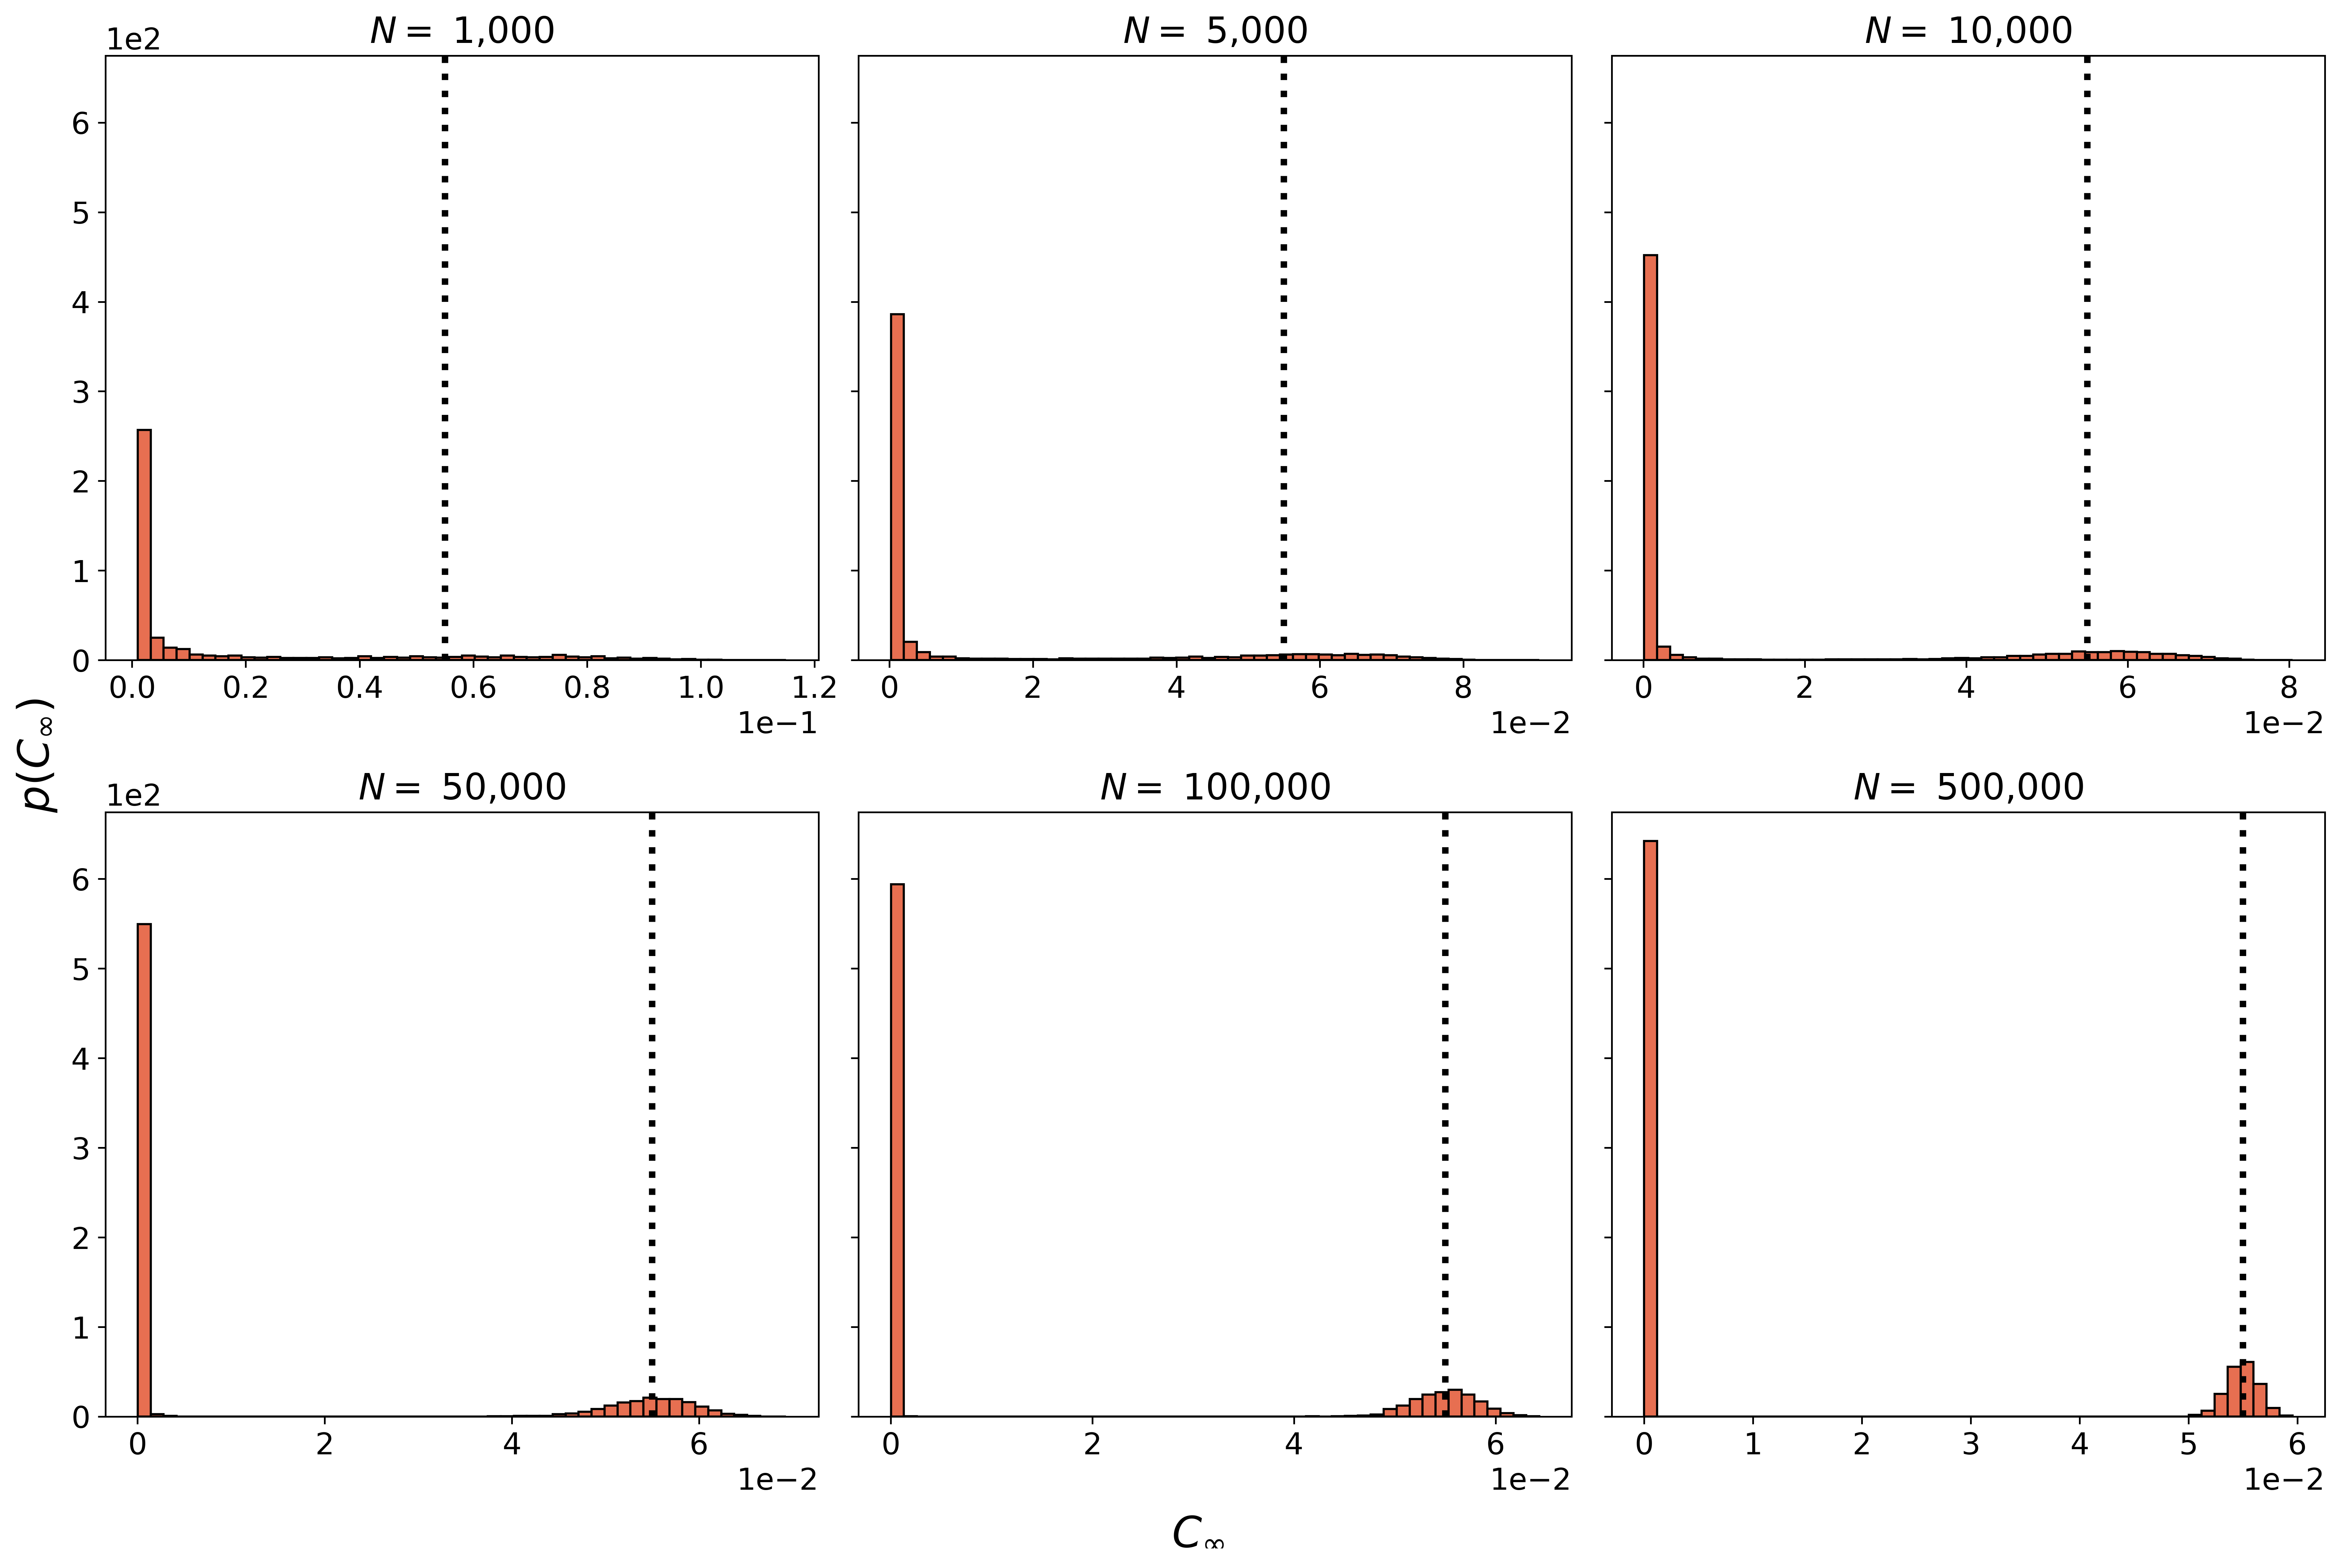

In [4]:
eps = 0.03
fig, axs = plt.subplots(2, 3, figsize=(15, 10), sharey=True)
for ax, N in zip(axs.flat, N_vec):
    cases_, _ = get(grid, N, eps)
    ax.hist(cases_ / N, color='#E76F51', edgecolor='black', density=True, bins=50)
    ax.set_title(rf'$N = $ {N:,}')
    ax.axvline(final_size_fraction(eps), color='k', linestyle=':', linewidth=3)
fig.text(0.5, -0.01, r'$C_{\infty}$', fontsize=20, ha='center')
fig.text(-0.01, 0.5, r'$p(C_{\infty})$', fontsize=20, va='center', rotation='vertical')
fig.tight_layout()
plt.savefig(f'{FIGS}/plot_paper_2.pdf', bbox_inches='tight')
plt.show()

# Figures 3a and 3b
Probability of a small (big) outbreak. Dashed black: branching process, p_s = 1/R_eff with R_eff = 1 + R0 ε (Whittle 1955; Allen 2017). Error bars: ±2 Monte Carlo standard errors.

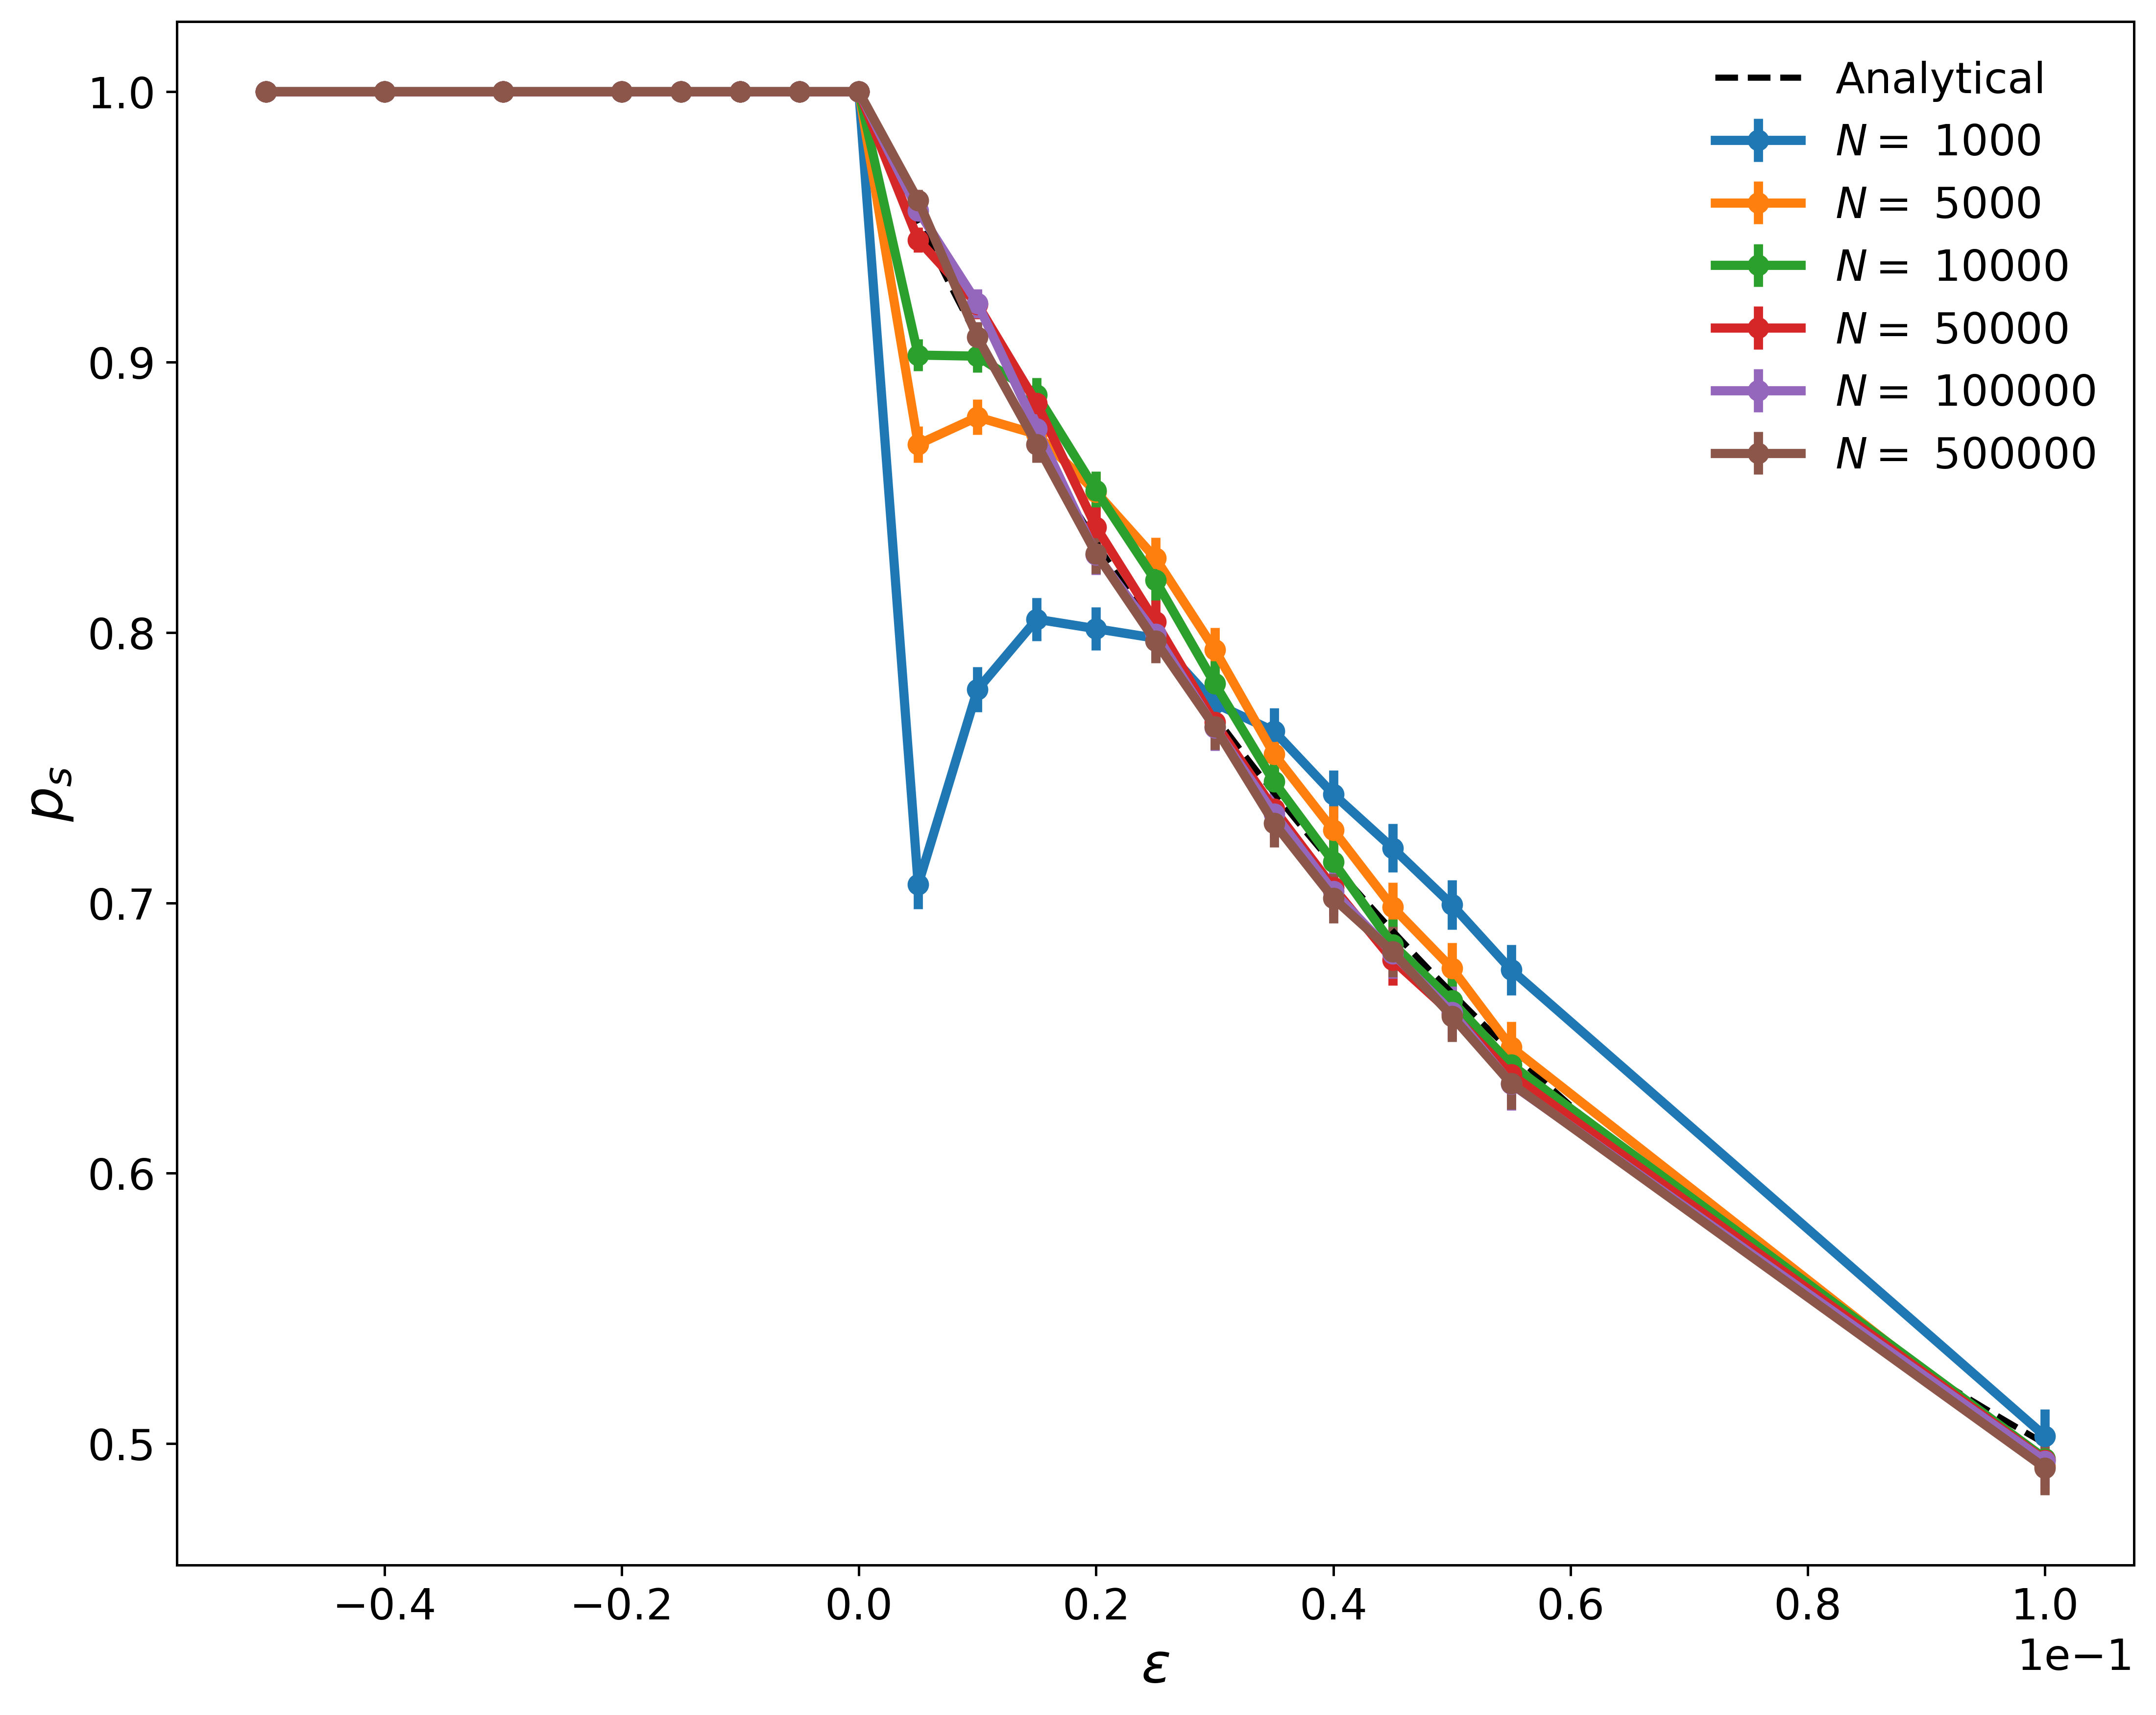

In [5]:
fig, ax = plt.subplots(figsize=(10, 8))
for N in N_vec:
    t = tab[tab.N == N]
    ax.errorbar(t.eps, t.p_s, yerr=2*t.se_p, fmt='-o', linewidth=3, color=colors[N], label=r'$N =$ ' + str(N))
ax.plot(eps_fine, p_small_theory(eps_fine), 'k--', linewidth=2, label='Analytical')
plt.xlabel(r'$\epsilon$', fontsize=18)
plt.ylabel(r'$p_s$', fontsize=18)
plt.legend()
plt.tight_layout()
plt.savefig(f'{FIGS}/plot_paper_3.pdf')
plt.show()

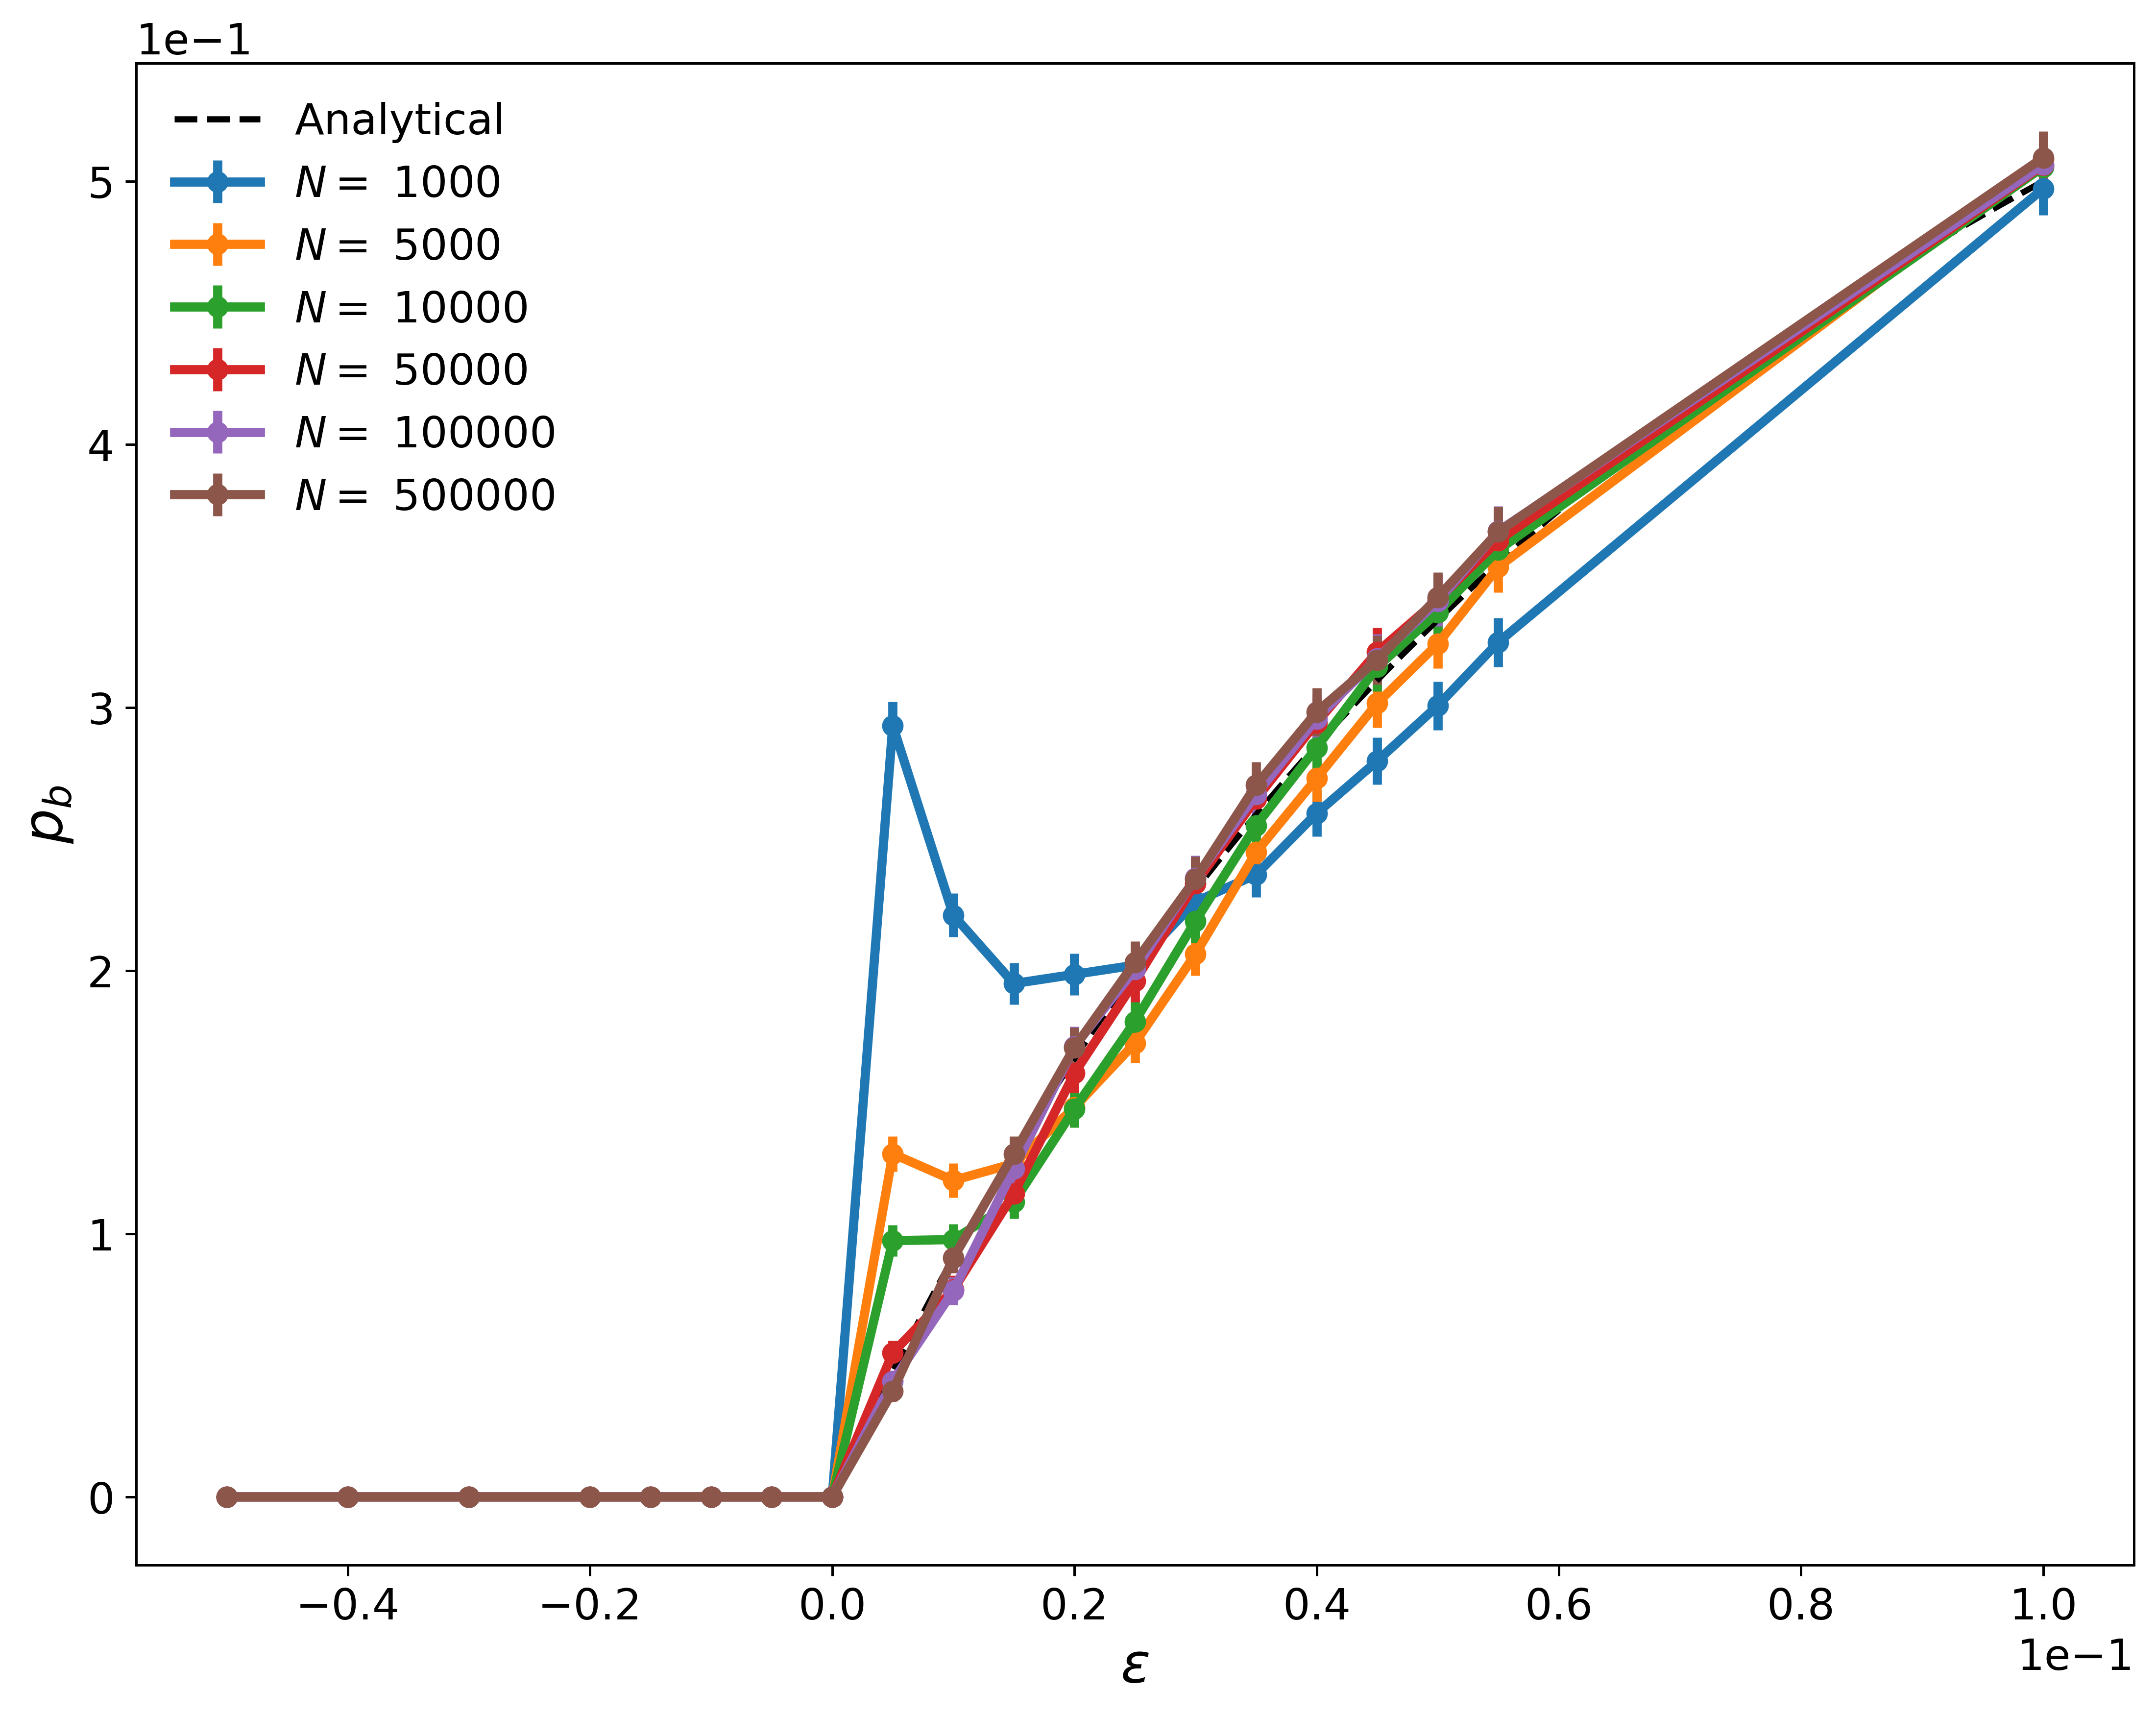

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))
for N in N_vec:
    t = tab[tab.N == N]
    ax.errorbar(t.eps, t.p_b, yerr=2*t.se_p, fmt='-o', linewidth=3, color=colors[N], label=r'$N =$ ' + str(N))
ax.plot(eps_fine, 1 - p_small_theory(eps_fine), 'k--', linewidth=2, label='Analytical')
plt.xlabel(r'$\epsilon$', fontsize=18)
plt.ylabel(r'$p_b$', fontsize=18)
plt.legend()
plt.tight_layout()
plt.savefig(f'{FIGS}/plot_paper_3_extra.pdf')
plt.show()

# Figures 4a and 4b
**4a** — mean size of big outbreaks (fraction of N), conditional on being big. Dashed: deterministic final size.

**4b** — mean size of small outbreaks, conditional on being small. Dashed: analyrtical result, 1/(1 − R_eff) for R_eff < 1 and R_eff/(R_eff − 1) for R_eff > 1 (diverges at ε = 0; finite N caps it).

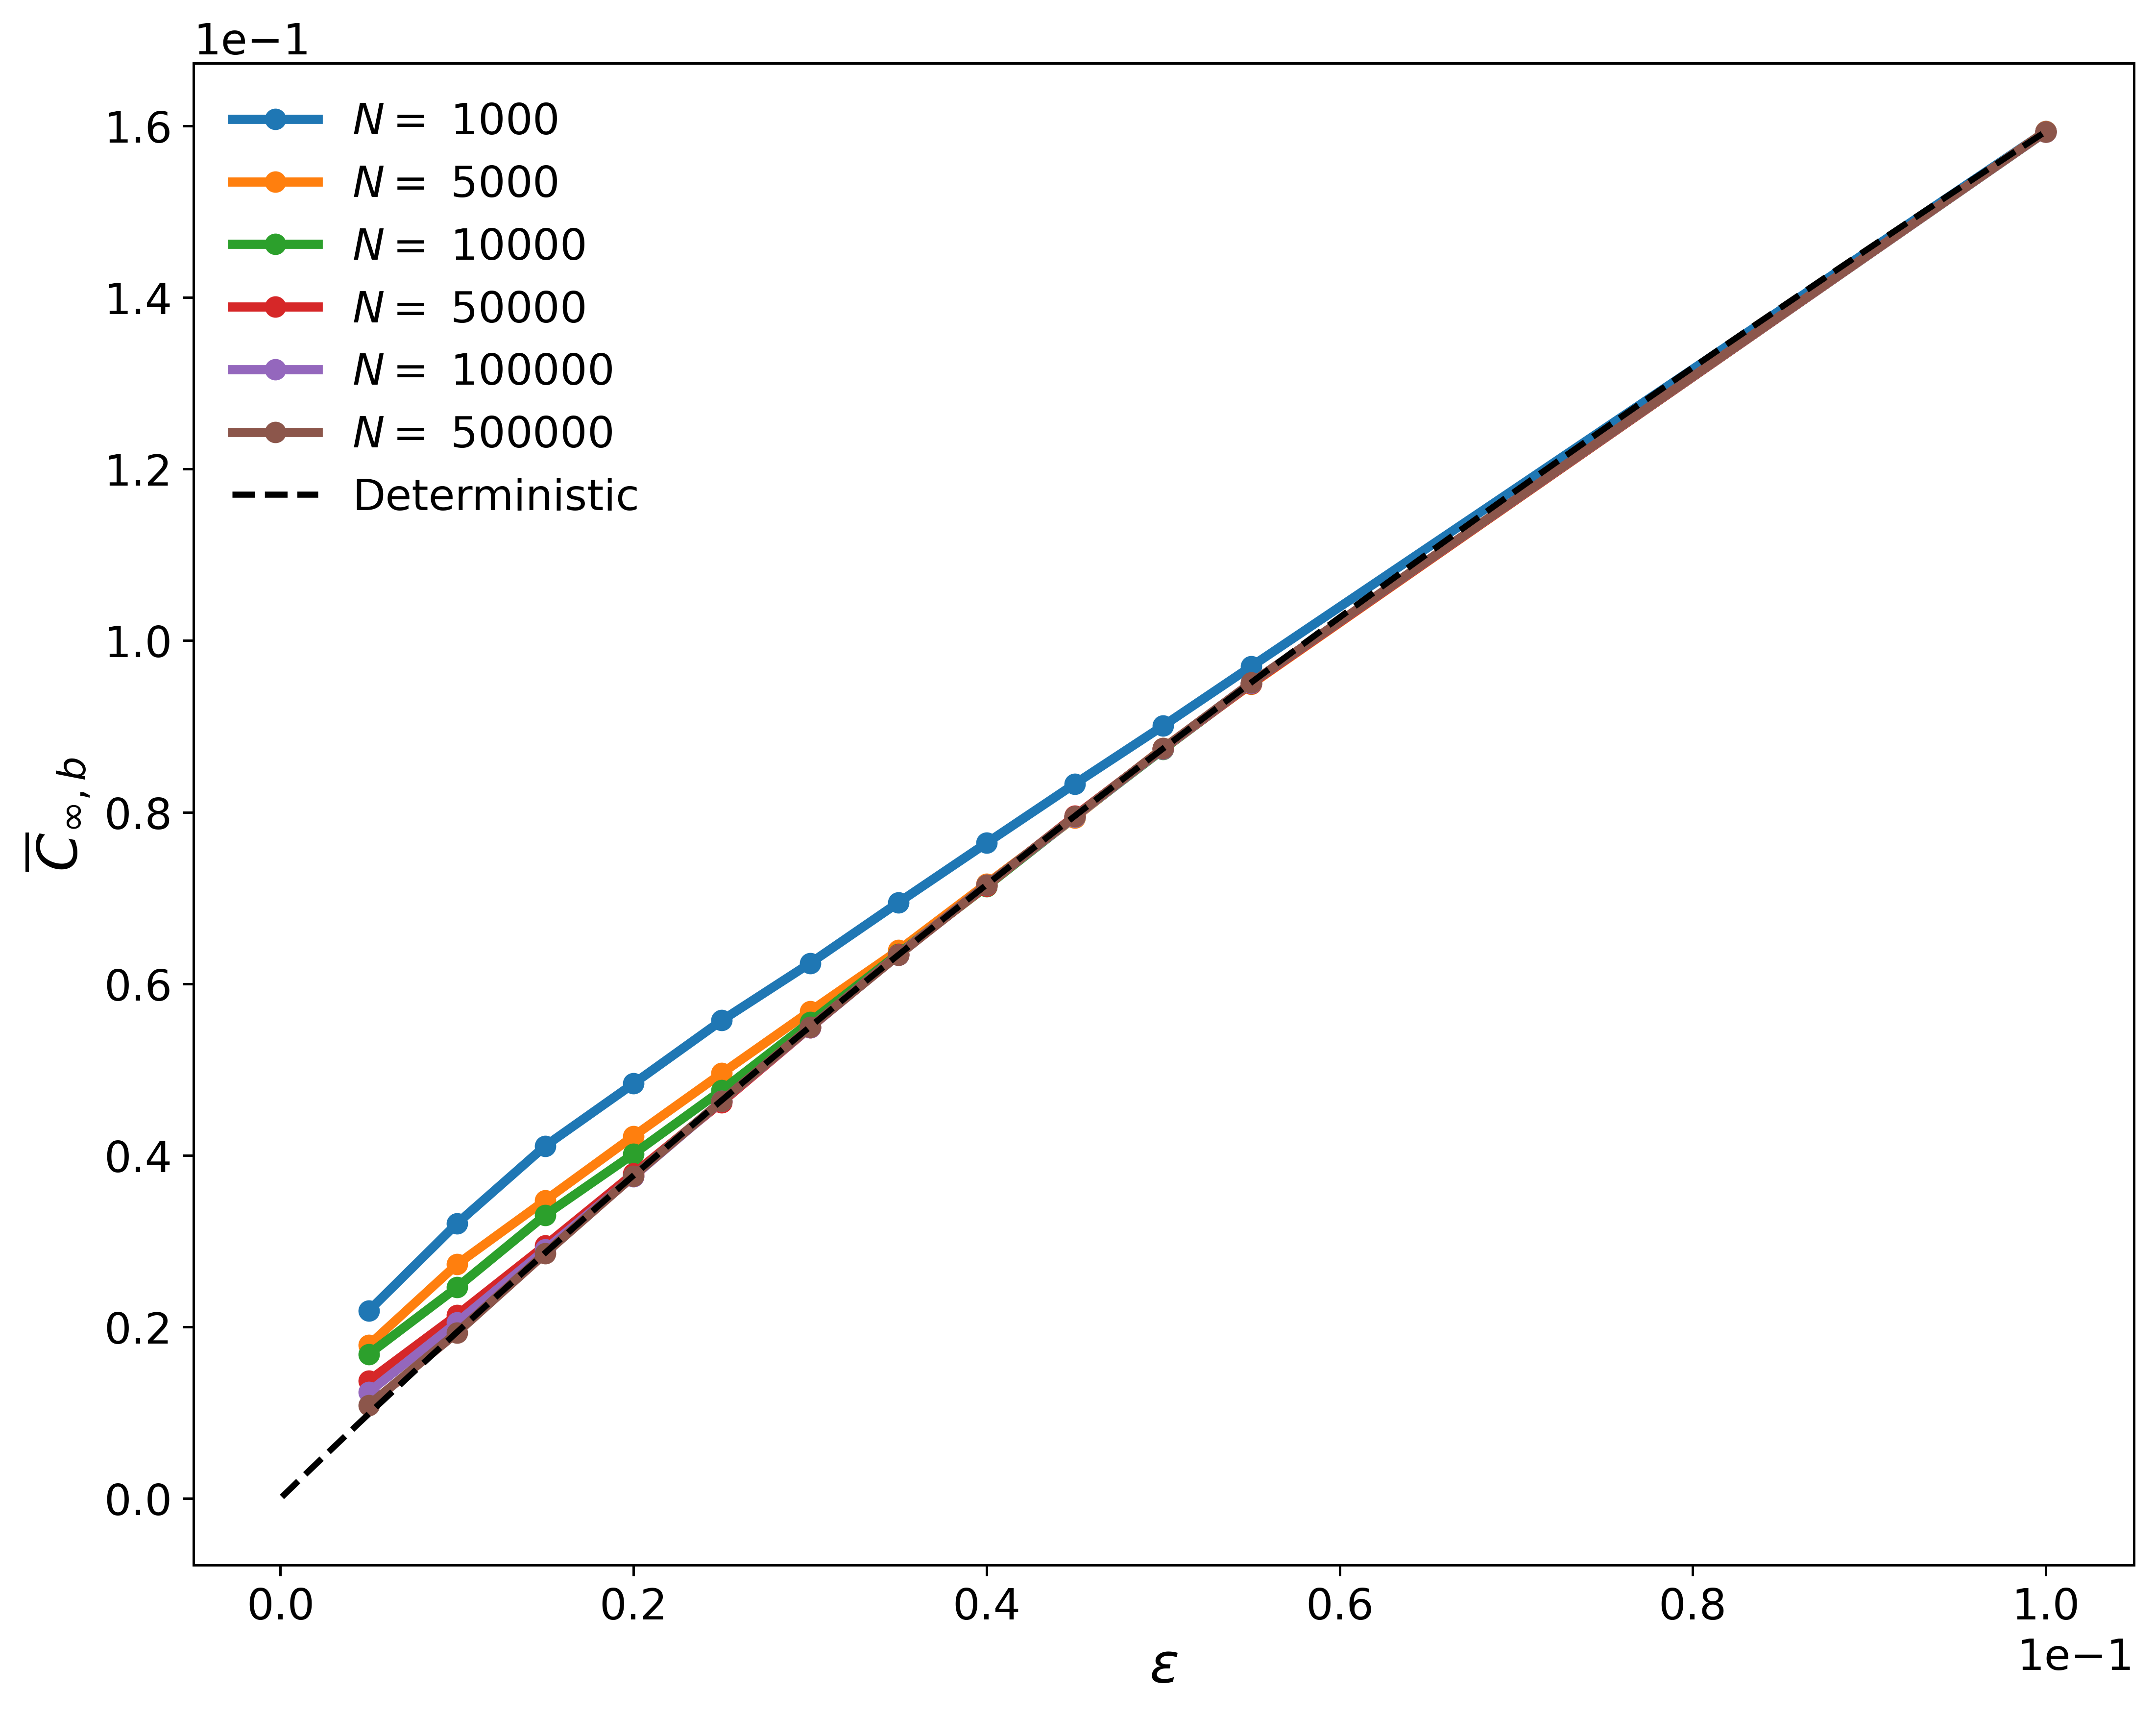

In [7]:
fig, ax = plt.subplots(figsize=(10, 8))
for N in N_vec:
    t = tab[(tab.N == N) & (tab.eps > 0)]
    ax.plot(t.eps, t.mean_big_cases / N, '-o', linewidth=3, color=colors[N], label=r'$N =$ ' + str(N))
ef = eps_fine[eps_fine > 0]
ax.plot(ef, [final_size_fraction(e) for e in ef], 'k--', linewidth=2, label='Deterministic')
plt.xlabel(r'$\epsilon$', fontsize=18)
plt.ylabel(r'$\overline{C}_{\infty,b}$', fontsize=18)
plt.legend()
fig.tight_layout()
plt.savefig(f'{FIGS}/plot_paper_4.pdf')
plt.show()

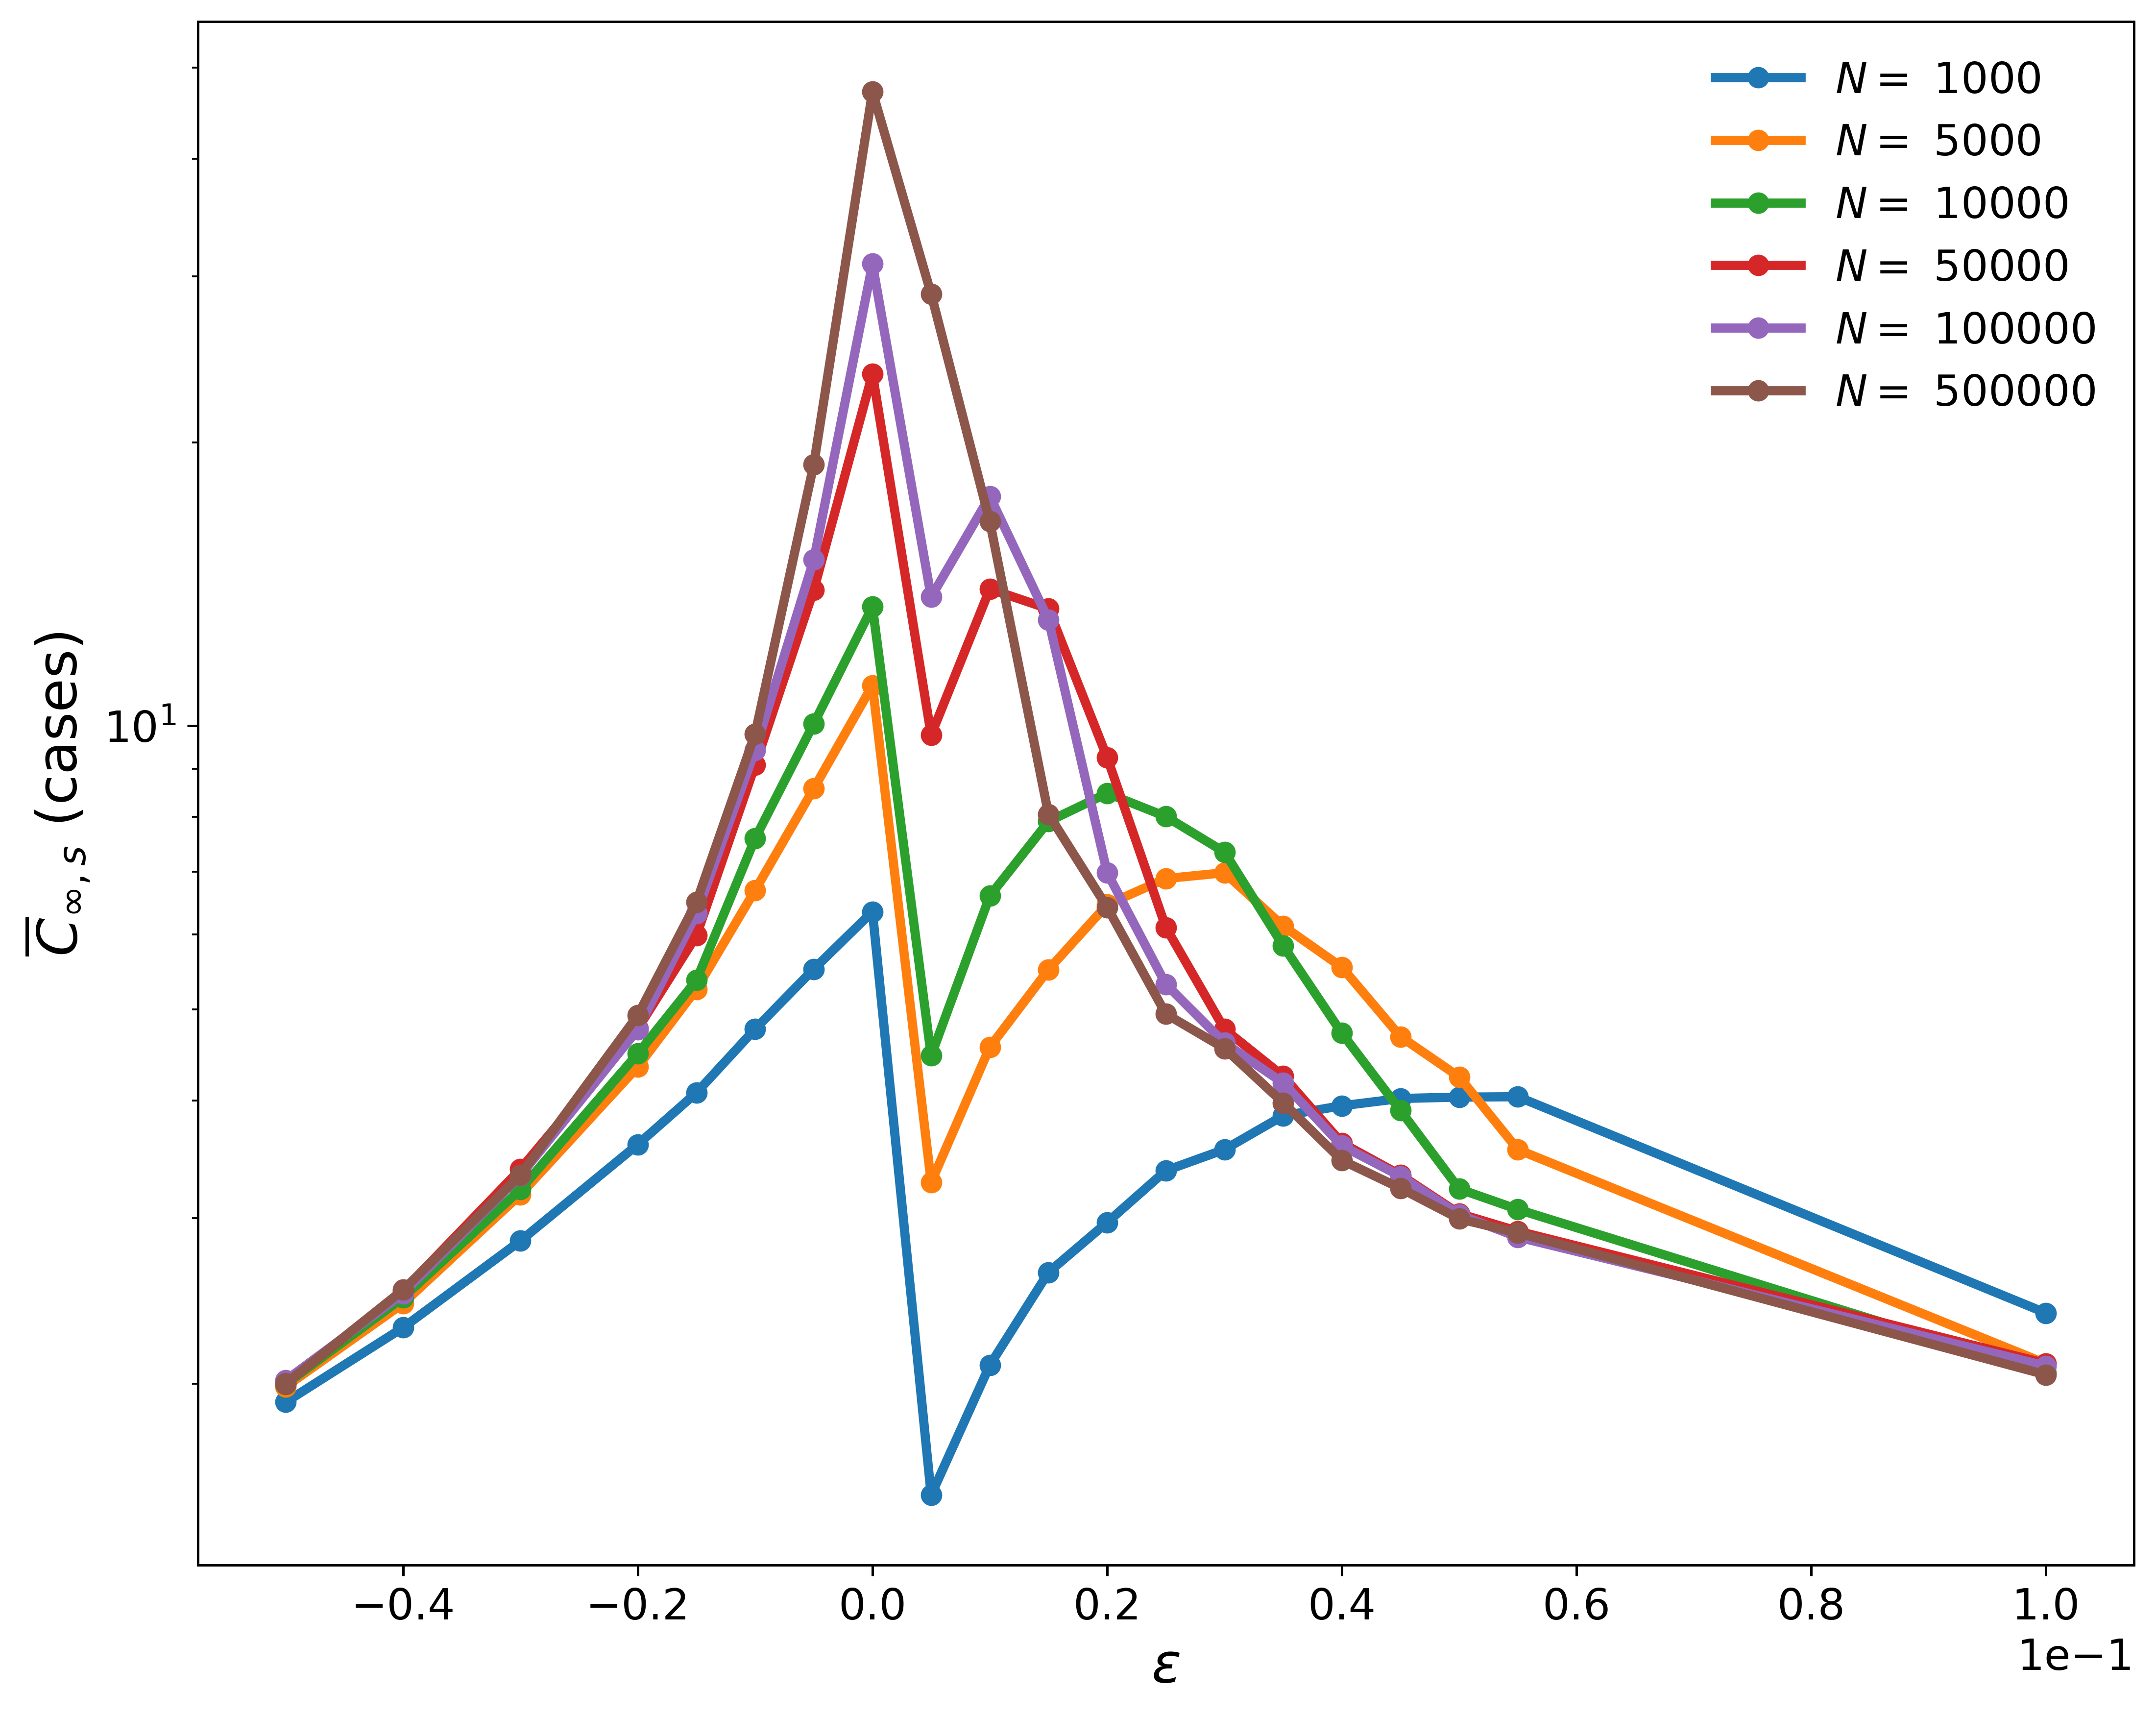

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
for N in N_vec:
    t = tab[tab.N == N]
    ax.plot(t.eps, t.mean_small_cases, '-o', linewidth=3, color=colors[N], label=r'$N =$ ' + str(N))
ax.set_yscale('log')
plt.xlabel(r'$\epsilon$', fontsize=18)
plt.ylabel(r'$\overline{C}_{\infty,s}$ (cases)', fontsize=18)
plt.legend()
fig.tight_layout()
plt.savefig(f'{FIGS}/plot_paper_5.pdf')
plt.show()